# 03 · Modelo 2 — Risco de atraso (classificação)
**Projeto ZelaBairro · Global Solution 2026/2 · IA & Chatbot**

**Integrantes (turma 1TDSPV):** Leonardo Afonço Sousa (RM 573982) · Syang Cristina Gomes Souza (RM 569259) ·
Matheus Jones Sousa de Freitas (RM 573559) · Vitor Goncalves de Souza (RM 569023) · Joao Machado Nascimento (RM 572364)

**Pergunta:** esta ocorrência vai passar do prazo de referência da sua categoria?

* Alvo: `atrasou` (1 = sim, 0 = não), com a **mesma regra da RN11**: `dias_para_resolver > nr_prazo_dias`
* Entradas: `categoria`, `subprefeitura`, `mes`, `dia_semana`
* Caminho seguido (como nas Aulas 05 e 06): **modelo que chuta** (baseline) → modelos interpretáveis (**Regressão Logística** e **Árvore de Decisão**)
  → **Random Forest**
* Métricas (as da Aula 06): **matriz de confusão, acurácia, precisão, recall, F1 e curva ROC / AUC**

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

RAIZ = os.path.abspath("..")           # este notebook roda dentro de notebooks/
sys.path.insert(0, RAIZ)               # para importar ml_utils e chatbot
from chatbot.intents import CATEGORIAS # tabela 6.4 do Documento Base (prazos e gravidades)

CAMINHO_DADOS = os.path.join(RAIZ, "data", "dados_sp156.csv")
df = pd.read_csv(CAMINHO_DADOS)
print(f"{len(df):,} linhas e {df.shape[1]} colunas carregadas de {os.path.relpath(CAMINHO_DADOS, RAIZ)}")
df.head()

982,475 linhas e 9 colunas carregadas de data/dados_sp156.csv


,categoria,subprefeitura,data_abertura,data_encerramento,mes,dia_semana,dias_para_resolver,nr_prazo_dias,atrasou
0,Descarte irregular de lixo,Freguesia/Brasilândia,2020-01-01,2020-03-17,1,2,76,10,1
1,Buraco na via,Freguesia/Brasilândia,2020-01-01,2020-01-14,1,2,13,15,0
2,Buraco na via,Freguesia/Brasilândia,2020-01-01,2020-03-16,1,2,75,15,1
3,Buraco na via,Santo Amaro,2020-01-01,2020-01-08,1,2,7,15,0
4,Buraco na via,São Mateus,2020-01-01,2020-04-23,1,2,113,15,1


## 1. Preparação e equilíbrio das classes

In [2]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from ml_utils import FEATURES, montar_pipeline

SEED = 42
X, y = df[FEATURES], df["atrasou"]
print("Distribuição do alvo:"); print(y.value_counts().rename({0: "no prazo (0)", 1: "atrasou (1)"}).to_frame("n").assign(pct=lambda d: (d.n / d.n.sum()).round(3)))
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print(f"\ntreino: {len(X_treino):,} | teste: {len(X_teste):,}")

Distribuição do alvo:
                   n    pct
atrasou                    
no prazo (0)  689718  0.702
atrasou (1)   292757  0.298



treino: 785,980 | teste: 196,495


A divisão é **estratificada** para manter a proporção de atrasos no treino e no teste. Se as classes forem
muito desiguais, a acurácia sozinha engana (um modelo que sempre diz "não atrasa" acertaria muito),
por isso olhamos também precisão, recall e F1 (Aula 06: **F1 é a métrica recomendada em base desbalanceada**; **recall** quando o falso
negativo é caro) e usamos `class_weight="balanced"`: ele dá mais peso aos atrasos durante o treino, para o modelo não "chutar" sempre
"no prazo" (o problema da acurácia ilusória da Aula 05).

## 2. Baseline e comparação de modelos

In [3]:
def metricas_de(pipe):
    p = pipe.predict(X_teste)
    proba = pipe.predict_proba(X_teste)[:, 1]
    return {"acuracia": accuracy_score(y_teste, p), "precisao": precision_score(y_teste, p, zero_division=0),
            "recall": recall_score(y_teste, p, zero_division=0), "f1": f1_score(y_teste, p, zero_division=0),
            "roc_auc": roc_auc_score(y_teste, proba)}

candidatos = {
    "Baseline (classe mais comum)": montar_pipeline(DummyClassifier(strategy="most_frequent")),
    "Regressão Logística (sem mês)": montar_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Árvore de Decisão (sem mês)": montar_pipeline(DecisionTreeClassifier(max_depth=10, min_samples_leaf=50, class_weight="balanced", random_state=SEED)),
    "Random Forest COM mês": montar_pipeline(RandomForestClassifier(n_estimators=60, min_samples_leaf=20, class_weight="balanced", n_jobs=-1, random_state=SEED), usar_mes=True),
    "Random Forest SEM mês": montar_pipeline(RandomForestClassifier(n_estimators=60, min_samples_leaf=20, class_weight="balanced", n_jobs=-1, random_state=SEED), usar_mes=False),
}
linhas = []
for nome, pipe in candidatos.items():
    pipe.fit(X_treino, y_treino)
    linhas.append({"modelo": nome, **metricas_de(pipe)})
pd.DataFrame(linhas).round(3).set_index("modelo")

,acuracia,precisao,recall,f1,roc_auc
modelo,,,,,
Baseline (classe mais comum),0.702,0.000,0.000,0.000,0.500
Regressão Logística (sem mês),0.624,0.425,0.735,0.538,0.739
Árvore de Decisão (sem mês),0.558,0.395,0.903,0.549,0.736
Random Forest COM mês,0.708,0.506,0.783,0.615,0.807
Random Forest SEM mês,0.650,0.448,0.751,0.561,0.759


**Como ler:** o baseline mostra a acurácia "de graça": como só ~30% dos chamados atrasam, dizer sempre "no prazo" acerta ~70%.
A Regressão Logística e a Árvore de Decisão são os modelos interpretáveis da aula; o Random Forest combina muitas árvores (Aula 05)
e é escolhido se ganhar deles em F1 e ROC AUC.
**Resultado honesto:** com `class_weight="balanced"` as florestas ficam **abaixo do baseline em acurácia**, porque trocam acurácia por recall
(preferem avisar risco a deixar passar um atraso). O ganho real está no **ROC AUC (~0,75 sem mês)**, que mostra que o modelo **ordena** bem
quem tem mais risco, e no **recall (~0,8)** para a classe "atrasou". O preço são muitos falsos positivos (veja a matriz de confusão e a
tabela de limiares). Diga isso na apresentação em vez de citar só a acurácia.

### Teste "no tempo": treinar em 2020–2022 e testar em 2023
A divisão aleatória mistura os anos; o uso real é **prever o futuro** com dados do passado. Esta comparação decide se o **mês** entra no modelo:

In [4]:
ano = pd.to_datetime(df["data_abertura"]).dt.year
tr_t = df[ano <= 2022].sample(250_000, random_state=SEED); te_t = df[ano == 2023].sample(80_000, random_state=SEED)
linhas = [{"modelo": "Baseline (classe mais comum)",
           "acuracia": max(te_t["atrasou"].mean(), 1 - te_t["atrasou"].mean()), "f1": 0.0, "roc_auc": 0.5}]
for nome, com_mes in [("Random Forest SEM mês", False), ("Random Forest COM mês", True)]:
    m_t = montar_pipeline(RandomForestClassifier(n_estimators=60, min_samples_leaf=20, class_weight="balanced", n_jobs=-1, random_state=SEED), usar_mes=com_mes).fit(tr_t[FEATURES], tr_t["atrasou"])
    pr = m_t.predict_proba(te_t[FEATURES])[:, 1]
    linhas.append({"modelo": nome, "acuracia": accuracy_score(te_t["atrasou"], pr >= .5), "f1": f1_score(te_t["atrasou"], pr >= .5), "roc_auc": roc_auc_score(te_t["atrasou"], pr)})
pd.DataFrame(linhas).round(3).set_index("modelo")

,acuracia,f1,roc_auc
modelo,,,
Baseline (classe mais comum),0.580,0.000,0.500
Random Forest SEM mês,0.672,0.578,0.774
Random Forest COM mês,0.645,0.588,0.689


Treinando em 2020–2022 e testando em 2023, o modelo **com** mês fica **pior** (principalmente no ROC AUC) que o **sem** mês: o mês aprende o que aconteceu
em cada mês daqueles anos (pandemia, mutirões), e isso não se repete. **Decisão:** o modelo final **não usa o mês** (a API ainda aceita `mes`, mas o
ignora). Para mudar: `usar_mes=True` em `montar_pipeline` e retreinar.

## 3. Ajuste de hiperparâmetros (busca pequena, modelo SEM mês)

In [5]:
from sklearn.model_selection import GridSearchCV

grade = {"modelo__min_samples_leaf": [10, 20, 50], "modelo__max_depth": [None, 16]}
busca = GridSearchCV(montar_pipeline(RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=SEED)), grade,
                     scoring="f1", cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=1)
# Busca numa AMOSTRA do treino (rápida); o modelo final usa TODO o treino.
amostra = X_treino.sample(min(30_000, len(X_treino)), random_state=SEED).index
busca.fit(X_treino.loc[amostra], y_treino.loc[amostra])
print("Melhores parâmetros (busca na amostra):", busca.best_params_)
print(f"F1 médio na validação cruzada (amostra): {busca.best_score_:.3f}")

Melhores parâmetros (busca na amostra): {'modelo__max_depth': 16, 'modelo__min_samples_leaf': 20}
F1 médio na validação cruzada (amostra): 0.563


## 4. Modelo final: avaliação no teste

In [6]:
melhores = {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()}
modelo = montar_pipeline(RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=SEED, **melhores)).fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)
print(classification_report(y_teste, previsoes, target_names=["no prazo", "atrasou"], zero_division=0))

              precision    recall  f1-score   support

    no prazo       0.88      0.51      0.65    137944
     atrasou       0.42      0.83      0.56     58551

    accuracy                           0.61    196495
   macro avg       0.65      0.67      0.60    196495
weighted avg       0.74      0.61      0.62    196495



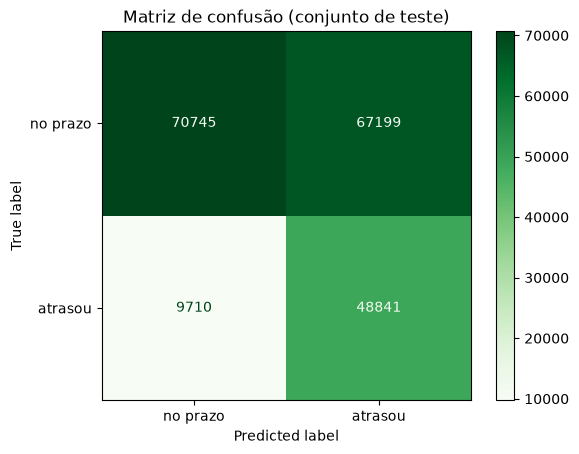

Verdadeiros negativos: 70745 | Falsos positivos: 67199 | Falsos negativos: 9710 | Verdadeiros positivos: 48841


In [7]:
cm = confusion_matrix(y_teste, previsoes, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["no prazo", "atrasou"]).plot(cmap="Greens", values_format="d")
plt.title("Matriz de confusão (conjunto de teste)"); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"Verdadeiros negativos: {tn} | Falsos positivos: {fp} | Falsos negativos: {fn} | Verdadeiros positivos: {tp}")

**Interpretação dos erros** (para a apresentação):
* *Falso positivo* — o modelo avisa risco de atraso e não atrasa: custo baixo (um alerta a mais).
* *Falso negativo* — o modelo não avisa e a ocorrência atrasa: é o erro mais caro para o cidadão.

In [8]:
base = candidatos["Baseline (classe mais comum)"]
metricas = {
    "acuracia": float(accuracy_score(y_teste, previsoes)), "precisao": float(precision_score(y_teste, previsoes, zero_division=0)),
    "recall": float(recall_score(y_teste, previsoes, zero_division=0)), "f1": float(f1_score(y_teste, previsoes, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_teste, modelo.predict_proba(X_teste)[:, 1])),
    "matriz_confusao": cm.tolist(), "baseline_acuracia": float(accuracy_score(y_teste, base.predict(X_teste))),
    "pct_atrasou_no_conjunto": float(y.mean()), "linhas_treino": int(len(X_treino)), "linhas_teste": int(len(X_teste)),
}
{k: (round(v, 3) if isinstance(v, float) else v) for k, v in metricas.items()}

{'acuracia': 0.609,
 'precisao': 0.421,
 'recall': 0.834,
 'f1': 0.559,
 'roc_auc': 0.754,
 'matriz_confusao': [[70745, 67199], [9710, 48841]],
 'baseline_acuracia': 0.702,
 'pct_atrasou_no_conjunto': 0.298,
 'linhas_treino': 785980,
 'linhas_teste': 196495}

In [9]:
amostra_cv = X.sample(min(60_000, len(X)), random_state=SEED).index
cv = cross_val_score(modelo, X.loc[amostra_cv], y.loc[amostra_cv], cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="f1")
print(f"Validação cruzada (5 folds, amostra de {len(amostra_cv):,}) — F1: {cv.mean():.3f} ± {cv.std():.3f}")

Validação cruzada (5 folds, amostra de 60,000) — F1: 0.556 ± 0.002


### Curva ROC (Aula 06)
A curva ROC mostra o compromisso entre a taxa de acertos genuínos (verdadeiros positivos) e a de alarmes falsos em todos os limiares.
Quanto mais a curva se afasta da diagonal (que é o "chute"), melhor; a **AUC** é a área sob a curva (0,5 = chute, 1 = perfeito).
Como na aula, usamos `predict_proba(X_teste)[:, 1]`, a probabilidade da classe "atrasou".

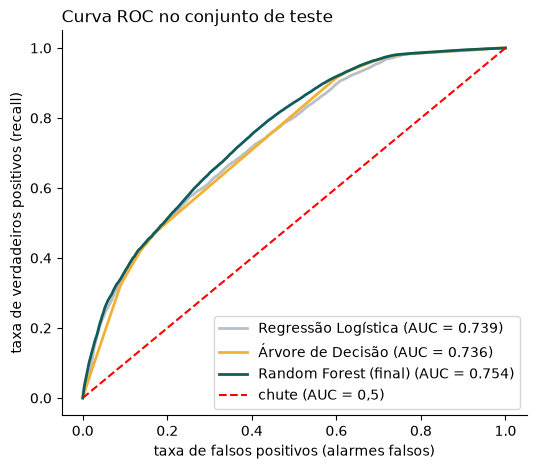

In [10]:
proba = modelo.predict_proba(X_teste)[:, 1]
fig, ax = plt.subplots(figsize=(6, 5))
for nome, pipe_cmp, cor in [("Regressão Logística", candidatos["Regressão Logística (sem mês)"], "#b8bfc6"),
                            ("Árvore de Decisão", candidatos["Árvore de Decisão (sem mês)"], "#f2b134"),
                            ("Random Forest (final)", modelo, "#0f5c5a")]:
    p_cmp = pipe_cmp.predict_proba(X_teste)[:, 1]
    taxa_falso_positivo, taxa_verdadeiro_positivo, limiares = roc_curve(y_teste, p_cmp)
    ax.plot(taxa_falso_positivo, taxa_verdadeiro_positivo, color=cor, lw=2, label=f"{nome} (AUC = {roc_auc_score(y_teste, p_cmp):.3f})")
ax.plot([0, 1], [0, 1], "r--", label="chute (AUC = 0,5)")
ax.set_xlabel("taxa de falsos positivos (alarmes falsos)"); ax.set_ylabel("taxa de verdadeiros positivos (recall)")
ax.set_title("Curva ROC no conjunto de teste", loc="left"); ax.legend(loc="lower right")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False); plt.show()

**A probabilidade é uma chance real?** Não exatamente. O `class_weight="balanced"` empurra as probabilidades para cima, então a
média prevista fica acima da taxa real de atrasos (célula abaixo). Por isso o ZelaBairro mostra ao cidadão só **risco alto/baixo**,
sem porcentagem.

In [11]:
print(f"Probabilidade média prevista de atraso: {proba.mean():.1%} | taxa real de atraso no teste: {y_teste.mean():.1%}")

Probabilidade média prevista de atraso: 46.2% | taxa real de atraso no teste: 29.8%


### Limiar de decisão
A API devolve `risco_atraso = "S"` quando `probabilidade >= 0.5`. Esse limiar **não** vem do Documento Base:
é a escolha padrão deste projeto. A tabela abaixo mostra o efeito de outros limiares; se o grupo quiser
mudar, atualize o documento (nova versão) e o `predictor.py`.

In [12]:
linhas = []
for lim in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba >= lim).astype(int)
    linhas.append({"limiar": lim, "precisao": precision_score(y_teste, p, zero_division=0),
                   "recall": recall_score(y_teste, p, zero_division=0), "f1": f1_score(y_teste, p, zero_division=0)})
pd.DataFrame(linhas).round(3).set_index("limiar")

,precisao,recall,f1
limiar,,,
0.3,0.367,0.973,0.533
0.4,0.392,0.923,0.550
0.5,0.421,0.834,0.559
0.6,0.564,0.438,0.493
0.7,0.646,0.298,0.408


### Importância das variáveis

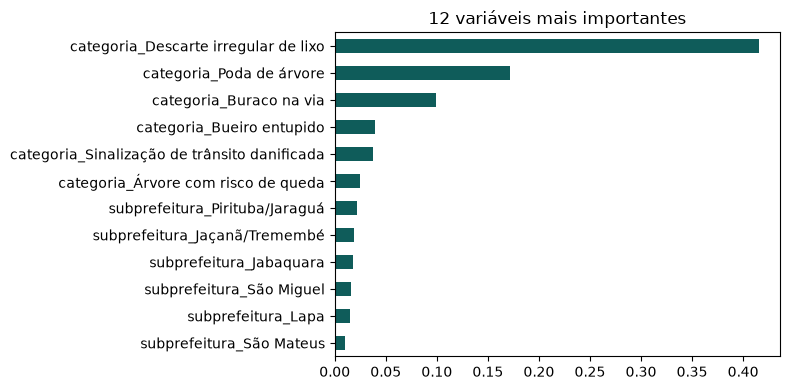

In [13]:
nomes = modelo.named_steps["prep"].get_feature_names_out()
imp = pd.Series(modelo.named_steps["modelo"].feature_importances_, index=nomes).sort_values(ascending=False)
imp.index = [i.replace("cat__", "") for i in imp.index]
imp.head(12).sort_values().plot.barh(figsize=(8, 4), color="#0f5c5a")
plt.title("12 variáveis mais importantes"); plt.tight_layout(); plt.show()

## 5. Exportar o modelo (`models/modelo_atraso.joblib`)

In [14]:
import joblib
os.makedirs(os.path.join(RAIZ, "models"), exist_ok=True)
modelo.fit(X, y)
joblib.dump({"pipeline": modelo, "metricas": metricas, "features": FEATURES, "usa_mes": False,
             "categorias_treino": {k: int(v) for k, v in df["categoria"].value_counts().items()}},
            os.path.join(RAIZ, "models", "modelo_atraso.joblib"), compress=3)
print("salvo em models/modelo_atraso.joblib")

salvo em models/modelo_atraso.joblib


In [15]:
exemplo = pd.DataFrame([{"categoria": "Buraco na via", "subprefeitura": df["subprefeitura"].iloc[0], "mes": 11, "dia_semana": 2}])
pipe = joblib.load(os.path.join(RAIZ, "models", "modelo_atraso.joblib"))["pipeline"]
p = float(pipe.predict_proba(exemplo)[0][list(pipe.classes_).index(1)])
print({"risco_atraso": "S" if p >= 0.5 else "N", "probabilidade": round(p, 2)})

{'risco_atraso': 'S', 'probabilidade': 0.51}


## 6. Conclusões
* **Comparação dos modelos (na ordem das aulas):** a Regressão Logística (F1 0,538, AUC 0,739) e a Árvore de Decisão (F1 0,549, AUC 0,736) já são bem melhores que chutar (AUC 0,5). A Árvore pega mais atrasos (recall 0,903), mas dá mais alarmes falsos (precisão 0,395). O Random Forest sem mês foi o melhor em F1 (0,561) e em AUC (0,759), as métricas que a aula indica para base desbalanceada. Com mês ele parece ainda melhor no teste aleatório (AUC 0,807), mas piora no teste no tempo, então ficou sem o mês.
* **A acurácia engana aqui:** o modelo final tem 0,609, menos que os 0,702 de quem sempre diz "no prazo". Isso acontece porque usamos `class_weight="balanced"` para o modelo não ignorar os atrasos. O que vale olhar é o AUC de 0,754 e o recall de 0,834.
* **Matriz de confusão (196.495 chamados de teste):** acertamos 48.841 atrasos e deixamos passar 9.710 (16,6% dos atrasos). Foram 67.199 alarmes falsos e 70.745 acertos de "no prazo". Precisão de 0,421 e F1 de 0,559. Na validação cruzada o F1 foi 0,556 ± 0,002, então o resultado se mantém.
* **Por que aceitamos tantos alarmes falsos:** para o cidadão, o pior erro é não avisar e o problema atrasar (falso negativo). Um alarme a mais só faz a ocorrência subir um pouco na fila do gestor.
* **Curva ROC:** a curva do Random Forest fica acima das curvas da Logística e da Árvore em quase todos os pontos (AUC 0,754 contra 0,739 e 0,736).
* **Limiar de decisão:** em 0,5, recall de 0,834 e precisão de 0,421. Em 0,3 o recall vai a 0,973 (precisão de 0,367). Em 0,6 a precisão sobe para 0,564, mas o recall cai para 0,438; em 0,7 fica em 0,646 e 0,298. Ficamos com 0,5.
* **A probabilidade não é uma chance real:** a média prevista é de 46,2%, mas só 29,8% dos chamados do teste atrasaram. Por isso, no site e no chatbot, mostramos só "risco alto" ou "risco baixo".
* **Hiperparâmetros:** o GridSearchCV, rodado numa amostra de 30 mil chamados, escolheu `max_depth=16`. No teste completo, a versão sem limite de profundidade ficou um pouco melhor (AUC 0,759 contra 0,754). A diferença é pequena; uma busca com amostra maior seria o próximo passo.
* **Limitações:** as mesmas do notebook 02. Com mais informação sobre cada chamado (descrição, gravidade real, local exato), o modelo poderia melhorar.